# Superstore Sales Analysis: Seasonality, Category Revenue & Discount Sensitivity

**Objective:** Analyze customer purchase volume, monthly seasonality, category-wise revenue and discount sensitivity, and turn the results into executive takeaways.

**Dataset:** Superstore Sales (US retail orders, Jan 2015 - Dec 2018)

**Workflow**
1. Load data and handle structural problems (appended lookup tables, nulls, duplicates)
2. Parse dates and engineer features (Year, Month, Year-Month, Profit Margin)
3. Aggregate Sales & Profit by Category, Region and Segment
4. Visualize monthly sales velocity and discount vs profit
5. Document business findings and recommendations

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

FILE = "superstore_sales.csv"   # update the path if the file is elsewhere
money = mtick.FuncFormatter(lambda x, _: f"${x/1e3:,.0f}K")
pct = mtick.PercentFormatter(1.0)

## 1. Load Data

The CSV is not a single clean table. Beyond the 9,994 order lines, the file has **two lookup tables appended below the data**
(a *People* table of regional managers and a *Returns* table of returned Order IDs). Pandas reads those as ~806 mostly-empty rows,
which is why every column shows 806 "nulls". We read everything as text first, locate the table boundaries, and split them apart
instead of blindly dropping nulls.

In [2]:
raw = pd.read_csv(FILE, encoding="latin-1", dtype=str)
print("Raw shape:", raw.shape)

# Locate the appended lookup tables by their header rows
people_start  = raw.index[raw["Row ID"] == "Person"][0]
returns_start = raw.index[raw["Row ID"] == "Returned"][0]
print(f"People table starts at row {people_start}, Returns table at row {returns_start}")

df      = raw.iloc[:people_start].copy()                                   # main orders table
people  = raw.iloc[people_start + 1:returns_start, :2].set_axis(["Person", "Region"], axis=1)
returns = raw.iloc[returns_start + 1:, :2].set_axis(["Returned", "Order ID"], axis=1)

print("Orders table:", df.shape, "| People table:", people.shape, "| Returns table:", returns.shape)
people

Raw shape: (10800, 21)
People table starts at row 9994, Returns table at row 9999
Orders table: (9994, 21) | People table: (4, 2) | Returns table: (800, 2)


,Person,Region
9995,Anna Andreadi,West
9996,Chuck Magee,East
9997,Kelly Williams,Central
9998,Cassandra Brandow,South


## 2. Data Cleaning

In [3]:
# --- 2.1 Fix data types -------------------------------------------------------
num_cols = ["Sales", "Quantity", "Discount", "Profit"]
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="raise")
df["Row ID"] = df["Row ID"].astype(int)

# --- 2.2 Parse dates (format is M/D/YYYY) -------------------------------------
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"]  = pd.to_datetime(df["Ship Date"],  format="%m/%d/%Y")

# --- 2.3 Null values ----------------------------------------------------------
print("Remaining nulls per column (orders table only):")
print(df.isna().sum()[lambda s: s > 0])

Remaining nulls per column (orders table only):
Postal Code    11
dtype: int64


In [4]:
# The only genuine nulls: Postal Code for Burlington, Vermont.
print(df.loc[df["Postal Code"].isna(), ["City", "State"]].drop_duplicates())

# Burlington, VT is a single city; fill with its ZIP code (05401) rather than dropping 11 valid sales rows.
mask = (df["City"] == "Burlington") & (df["State"] == "Vermont") & df["Postal Code"].isna()
df.loc[mask, "Postal Code"] = "05401"
df["Postal Code"] = df["Postal Code"].str.replace(r"\.0$", "", regex=True).str.zfill(5)

print("\nNulls remaining:", int(df.isna().sum().sum()))

            City    State
2234  Burlington  Vermont

Nulls remaining: 0


In [5]:
# --- 2.4 Duplicates & integrity checks ---------------------------------------
print("Duplicate Row IDs:           ", df["Row ID"].duplicated().sum())
print("Fully duplicated rows:       ", df.duplicated().sum())
print("Ship date before order date: ", (df["Ship Date"] < df["Order Date"]).sum())
print("Negative / zero sales:       ", (df["Sales"] <= 0).sum())
print("Discount outside 0-1:        ", (~df["Discount"].between(0, 1)).sum())
print("Date range:", df["Order Date"].min().date(), "->", df["Order Date"].max().date())

Duplicate Row IDs:            0
Fully duplicated rows:        0
Ship date before order date:  0
Negative / zero sales:        0
Discount outside 0-1:         0
Date range: 2015-01-03 -> 2018-12-30


In [6]:
# --- 2.5 Feature engineering --------------------------------------------------
df["Year"]        = df["Order Date"].dt.year
df["Month"]       = df["Order Date"].dt.month
df["Month Name"]  = df["Order Date"].dt.strftime("%b")
df["Quarter"]     = df["Order Date"].dt.quarter
df["Year-Month"]  = df["Order Date"].dt.to_period("M")
df["Profit Margin"] = df["Profit"] / df["Sales"]
df["Ship Days"]   = (df["Ship Date"] - df["Order Date"]).dt.days
df["Loss Making"] = df["Profit"] < 0
df["Returned"]    = df["Order ID"].isin(set(returns["Order ID"]))

# Discount bands used for the sensitivity analysis
df["Discount Band"] = pd.cut(
    df["Discount"], bins=[-0.01, 0, 0.20, 0.40, 0.80],
    labels=["No discount", "1-20%", "21-40%", "41-80%"]
)

print(f"Clean dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
df[["Order ID", "Order Date", "Year-Month", "Category", "Region", "Segment", "Sales", "Discount", "Profit", "Profit Margin"]].head()

Clean dataset: 9,994 rows x 31 columns


,Order ID,Order Date,Year-Month,Category,Region,Segment,Sales,Discount,Profit,Profit Margin
0,CA-2017-152156,2017-11-08,2017-11,Furniture,South,Consumer,261.9600,0.00,41.9136,0.1600
1,CA-2017-152156,2017-11-08,2017-11,Furniture,South,Consumer,731.9400,0.00,219.5820,0.3000
2,CA-2017-138688,2017-06-12,2017-06,Office Supplies,West,Corporate,14.6200,0.00,6.8714,0.4700
3,US-2016-108966,2016-10-11,2016-10,Furniture,South,Consumer,957.5775,0.45,-383.0310,-0.4000
4,US-2016-108966,2016-10-11,2016-10,Office Supplies,South,Consumer,22.3680,0.20,2.5164,0.1125


**Cleaning summary:** separated two appended lookup tables from the orders data, converted text columns to numeric/datetime types,
imputed 11 missing Burlington (VT) postal codes, and confirmed there are no duplicate rows, invalid dates or invalid discounts.
Final analysis table: **9,994 order lines**.

## 3. Headline KPIs

In [7]:
total_sales, total_profit = df["Sales"].sum(), df["Profit"].sum()
kpis = pd.Series({
    "Total Sales ($)": total_sales,
    "Total Profit ($)": total_profit,
    "Overall Profit Margin": total_profit / total_sales,
    "Order Lines": len(df),
    "Unique Orders": df["Order ID"].nunique(),
    "Unique Customers": df["Customer ID"].nunique(),
    "Avg Order Value ($)": total_sales / df["Order ID"].nunique(),
    "Loss-Making Lines (%)": df["Loss Making"].mean(),
    "Orders Returned (%)": df.drop_duplicates("Order ID")["Returned"].mean(),
})
kpis.map(lambda v: f"{v:,.3f}" if abs(v) < 1 else f"{v:,.0f}").to_frame("Value")

,Value
Total Sales ($),"2,297,201"
Total Profit ($),"286,397"
Overall Profit Margin,0.125
Order Lines,"9,994"
Unique Orders,"5,009"
Unique Customers,793
Avg Order Value ($),459
Loss-Making Lines (%),0.187
Orders Returned (%),0.059


In [8]:
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly["Margin"] = yearly["Profit"] / yearly["Sales"]
yearly["Sales YoY"] = yearly["Sales"].pct_change()
yearly.style.format({"Sales": "${:,.0f}", "Profit": "${:,.0f}", "Margin": "{:.1%}", "Sales YoY": "{:+.1%}"})

,Sales,Profit,Margin,Sales YoY
Year,,,,
2015,"$484,247","$49,544",10.2%,+nan%
2016,"$470,533","$61,619",13.1%,-2.8%
2017,"$609,206","$81,795",13.4%,+29.5%
2018,"$733,215","$93,439",12.7%,+20.4%


## 4. Aggregate Sales & Profit by Category, Region and Segment

In [9]:
def summarize(by):
    out = df.groupby(by).agg(
        Sales=("Sales", "sum"), Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique"), Avg_Discount=("Discount", "mean")
    )
    out["Margin"] = out["Profit"] / out["Sales"]
    return out.sort_values("Sales", ascending=False)

fmt = {"Sales": "${:,.0f}", "Profit": "${:,.0f}", "Margin": "{:.1%}", "Avg_Discount": "{:.1%}", "Orders": "{:,}"}

for dim in ["Category", "Region", "Segment"]:
    print(f"\n=== By {dim} ===")
    display(summarize(dim).style.format(fmt))


=== By Category ===


,Sales,Profit,Orders,Avg_Discount,Margin
Category,,,,,
Technology,"$836,154","$145,455","1,544",13.2%,17.4%
Furniture,"$742,000","$18,451","1,764",17.4%,2.5%
Office Supplies,"$719,047","$122,491","3,742",15.7%,17.0%



=== By Region ===


,Sales,Profit,Orders,Avg_Discount,Margin
Region,,,,,
West,"$725,458","$108,418","1,611",10.9%,14.9%
East,"$678,781","$91,523","1,401",14.5%,13.5%
Central,"$501,240","$39,706","1,175",24.0%,7.9%
South,"$391,722","$46,749",822,14.7%,11.9%



=== By Segment ===


,Sales,Profit,Orders,Avg_Discount,Margin
Segment,,,,,
Consumer,"$1,161,401","$134,119","2,586",15.8%,11.5%
Corporate,"$706,146","$91,979","1,514",15.8%,13.0%
Home Office,"$429,653","$60,299",909,14.7%,14.0%


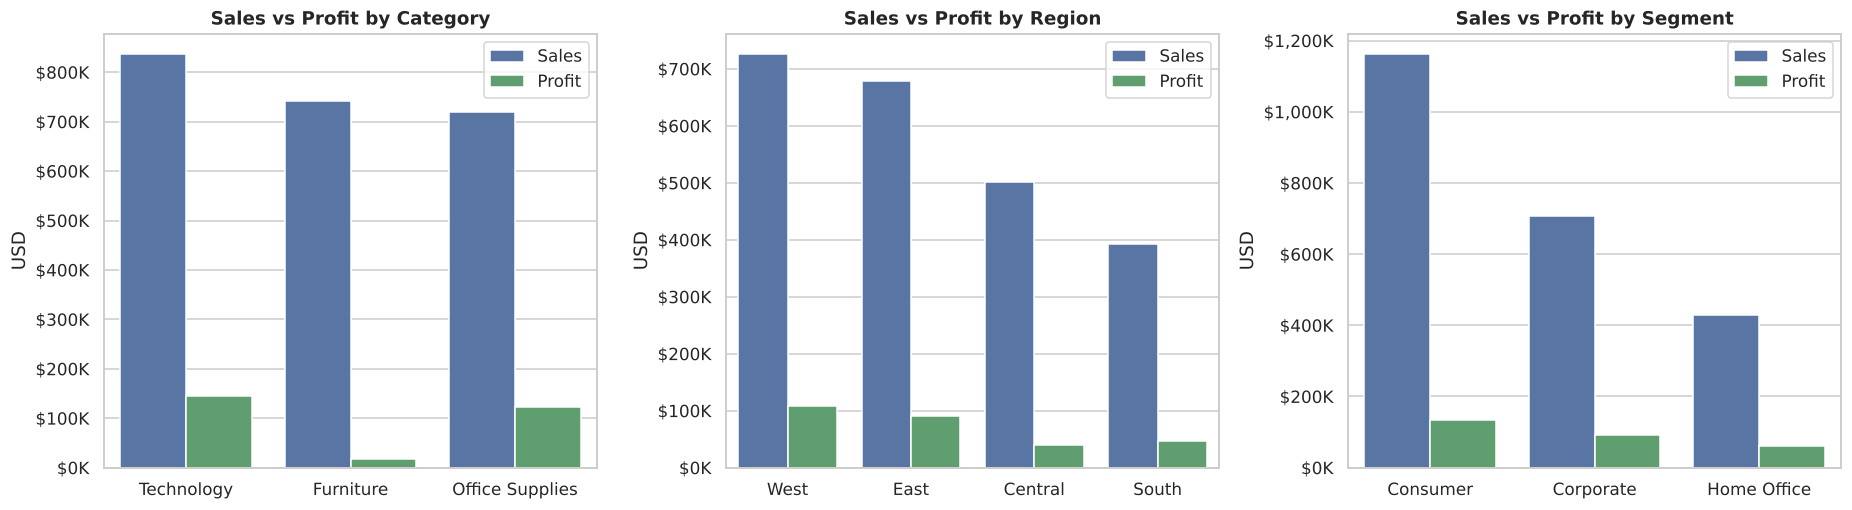

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, dim in zip(axes, ["Category", "Region", "Segment"]):
    s = summarize(dim)[["Sales", "Profit"]].reset_index().melt(id_vars=dim, var_name="Metric", value_name="USD")
    sns.barplot(data=s, x=dim, y="USD", hue="Metric", ax=ax, palette=["#4C72B0", "#55A868"])
    ax.yaxis.set_major_formatter(money)
    ax.set_title(f"Sales vs Profit by {dim}")
    ax.set_xlabel("")
    ax.legend(title="", loc="upper right")
plt.tight_layout()
plt.show()

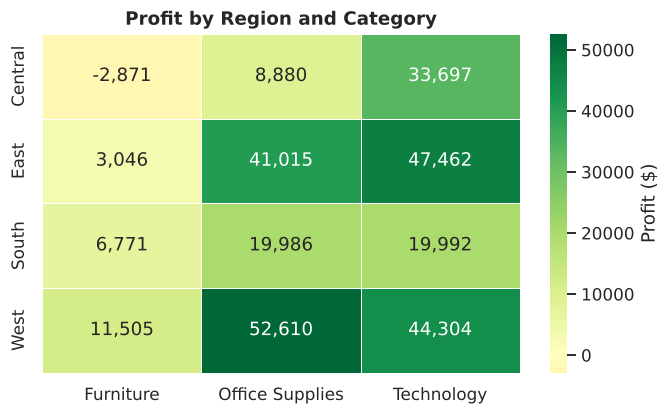

In [11]:
# Category x Region profit heatmap shows exactly where profit is made / lost
heat = df.pivot_table(index="Region", columns="Category", values="Profit", aggfunc="sum")
plt.figure(figsize=(7, 4))
sns.heatmap(heat, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, linewidths=.5, cbar_kws={"label": "Profit ($)"})
plt.title("Profit by Region and Category")
plt.ylabel(""); plt.xlabel("")
plt.show()

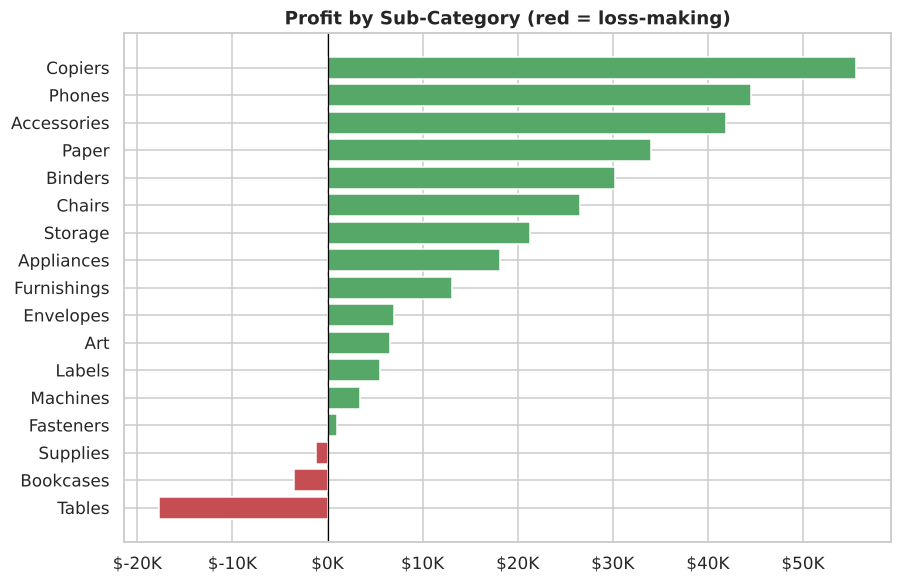

In [12]:
# Sub-category profitability: which products drive or destroy profit?
sub = df.groupby(["Category", "Sub-Category"]).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).reset_index()
sub["Margin"] = sub["Profit"] / sub["Sales"]
sub = sub.sort_values("Profit")

plt.figure(figsize=(9, 6))
colors = sub["Profit"].map(lambda v: "#C44E52" if v < 0 else "#55A868")
plt.barh(sub["Sub-Category"], sub["Profit"], color=colors)
plt.gca().xaxis.set_major_formatter(money)
plt.axvline(0, color="black", lw=.8)
plt.title("Profit by Sub-Category (red = loss-making)")
plt.show()

## 5. Monthly Sales Velocity & Seasonality

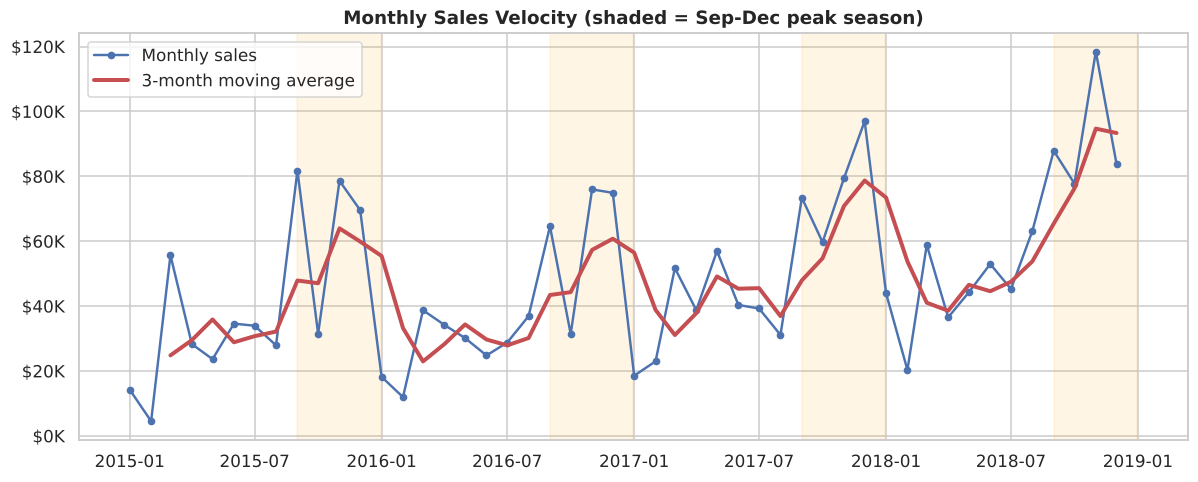

In [13]:
monthly = df.groupby("Year-Month").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
monthly.index = monthly.index.to_timestamp()
monthly["Sales 3M Avg"] = monthly["Sales"].rolling(3).mean()

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(monthly.index, monthly["Sales"], marker="o", ms=4, lw=1.6, label="Monthly sales")
ax.plot(monthly.index, monthly["Sales 3M Avg"], lw=2.6, color="#C44E52", label="3-month moving average")
for y in range(2015, 2019):
    ax.axvspan(pd.Timestamp(f"{y}-09-01"), pd.Timestamp(f"{y}-12-31"), color="orange", alpha=.10)
ax.yaxis.set_major_formatter(money)
ax.set_title("Monthly Sales Velocity (shaded = Sep-Dec peak season)")
ax.legend(loc="upper left")
plt.show()

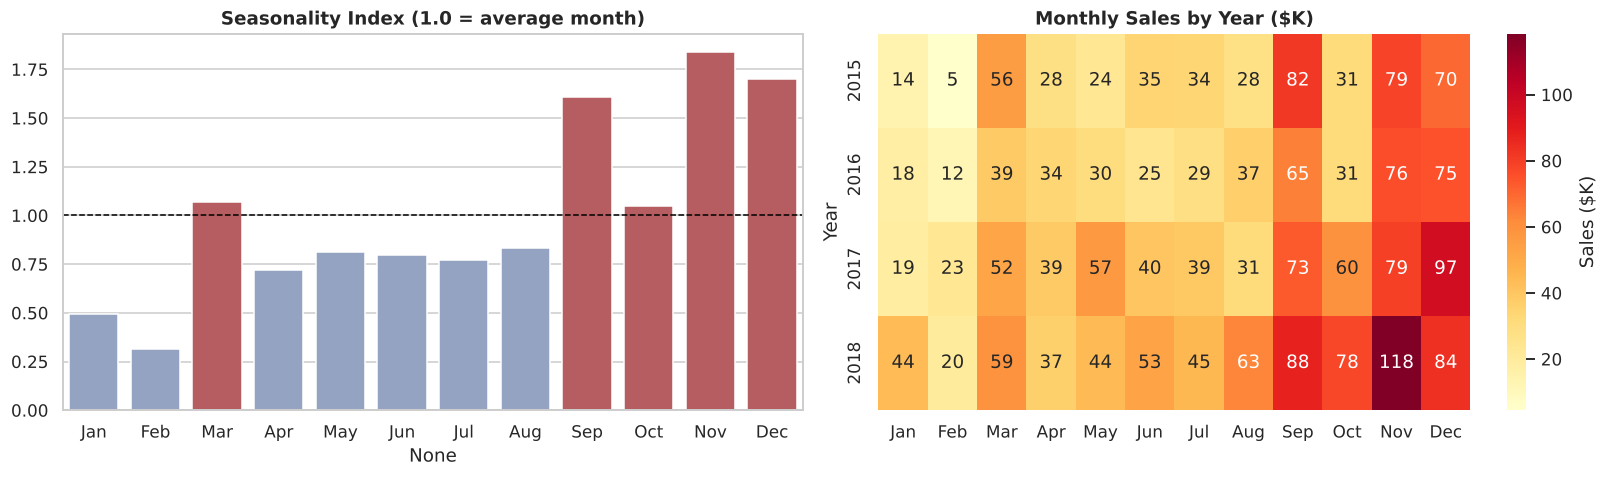

Share of sales by quarter:
 Quarter
1    15.7%
2    19.4%
3    26.7%
4    38.2%


In [14]:
# Seasonality index: average month sales / average of all months (1.0 = typical month)
by_month = df.groupby(["Year", "Month"])["Sales"].sum().groupby("Month").mean()
season_idx = (by_month / by_month.mean()).rename("Seasonality Index")
season_idx.index = pd.Index(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(x=season_idx.index, y=season_idx.values, ax=axes[0],
            palette=["#C44E52" if v >= 1.0 else "#8da0cb" for v in season_idx.values])
axes[0].axhline(1, color="black", ls="--", lw=1)
axes[0].set_title("Seasonality Index (1.0 = average month)")

heat_m = df.pivot_table(index="Year", columns="Month", values="Sales", aggfunc="sum")
heat_m.columns = season_idx.index
sns.heatmap(heat_m / 1e3, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Sales ($K)"})
axes[1].set_title("Monthly Sales by Year ($K)")
plt.tight_layout()
plt.show()

q = df.groupby("Quarter")["Sales"].sum()
print("Share of sales by quarter:\n", (q / q.sum()).map("{:.1%}".format).to_string())

## 6. Discount Sensitivity: Discount vs Profit

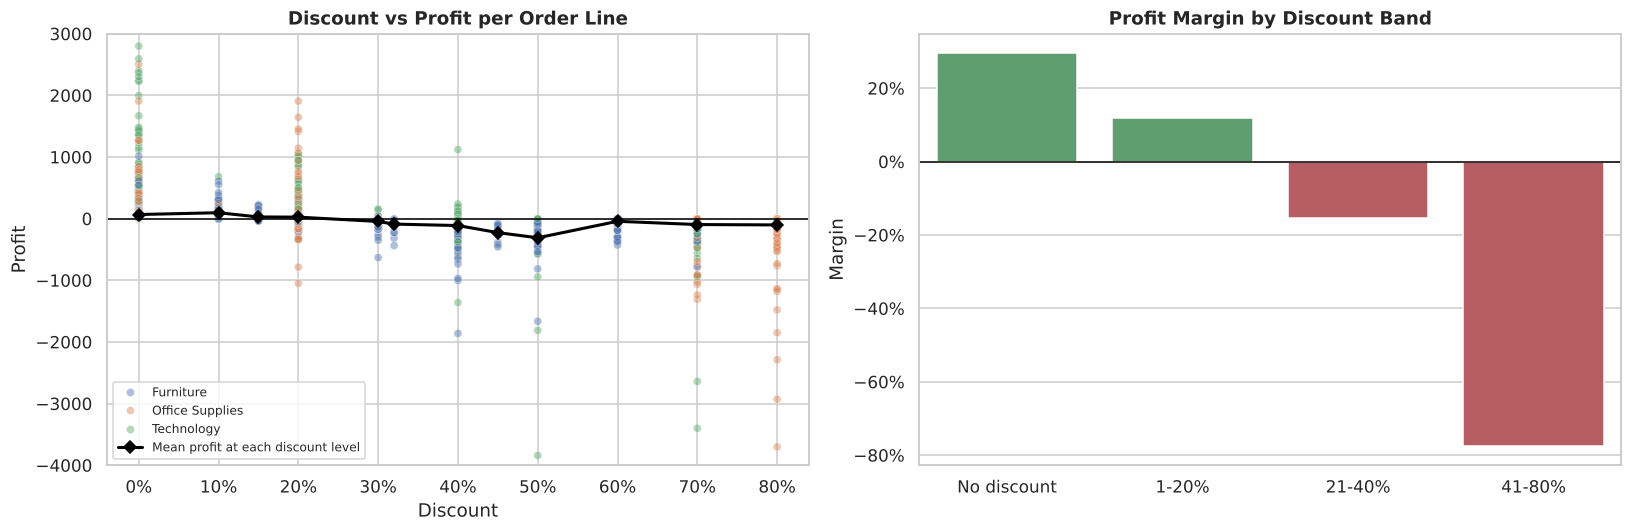

Correlation (Discount, Profit): -0.219


,Sales,Profit,Lines,Margin
Discount Band,,,,
No discount,"$1,087,908","$320,988","4,798",29.5%
1-20%,"$846,522","$100,785","3,803",11.9%
21-40%,"$234,138","$-35,817",460,-15.3%
41-80%,"$128,632","$-99,559",933,-77.4%


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=df, x="Discount", y="Profit", hue="Category", alpha=.45, s=28, ax=axes[0])
axes[0].axhline(0, color="black", lw=1)
axes[0].set_ylim(-4000, 3000)   # zoom past a handful of extreme outliers
axes[0].xaxis.set_major_formatter(pct)
axes[0].set_title("Discount vs Profit per Order Line")

avg_profit = df.groupby("Discount")["Profit"].mean()
axes[0].plot(avg_profit.index, avg_profit.values, color="black", marker="D", lw=2, label="Mean profit at each discount level")
axes[0].legend(loc="lower left", fontsize=8)

band = df.groupby("Discount Band").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Lines=("Sales", "size"))
band["Margin"] = band["Profit"] / band["Sales"]
sns.barplot(x=band.index.astype(str), y=band["Margin"], ax=axes[1],
            palette=["#55A868" if m > 0 else "#C44E52" for m in band["Margin"]])
axes[1].yaxis.set_major_formatter(pct)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("Profit Margin by Discount Band")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

print("Correlation (Discount, Profit):", round(df["Discount"].corr(df["Profit"]), 3))
band.style.format({"Sales": "${:,.0f}", "Profit": "${:,.0f}", "Margin": "{:.1%}", "Lines": "{:,}"})

In [16]:
# Where does the discount damage concentrate?
heavy = df[df["Discount"] >= 0.30]
print(f"Lines with discount >= 30%: {len(heavy):,} ({len(heavy)/len(df):.1%} of lines)")
print(f"Profit on those lines:      ${heavy['Profit'].sum():,.0f}")
print(f"Total loss on ALL loss-making lines: ${df.loc[df['Loss Making'], 'Profit'].sum():,.0f}")

disc_region = df.groupby("Region").apply(lambda x: pd.Series({
    "Avg Discount": x["Discount"].mean(),
    "% of Sales Discounted >20%": x.loc[x["Discount"] > .2, "Sales"].sum() / x["Sales"].sum(),
    "Margin": x["Profit"].sum() / x["Sales"].sum(),
})).sort_values("Margin")
disc_region.style.format("{:.1%}")

Lines with discount >= 30%: 1,393 (13.9% of lines)
Profit on those lines:      $-135,376
Total loss on ALL loss-making lines: $-156,131


,Avg Discount,% of Sales Discounted >20%,Margin
Region,,,
Central,24.0%,25.8%,7.9%
South,14.7%,18.1%,11.9%
East,14.5%,21.5%,13.5%
West,10.9%,2.4%,14.9%


## 7. Customer Purchase Volume

Customers: 793 | Repeat customers (>1 order): 98.5%
Median orders per customer: 6
Top 20% of customers generate 48.0% of sales


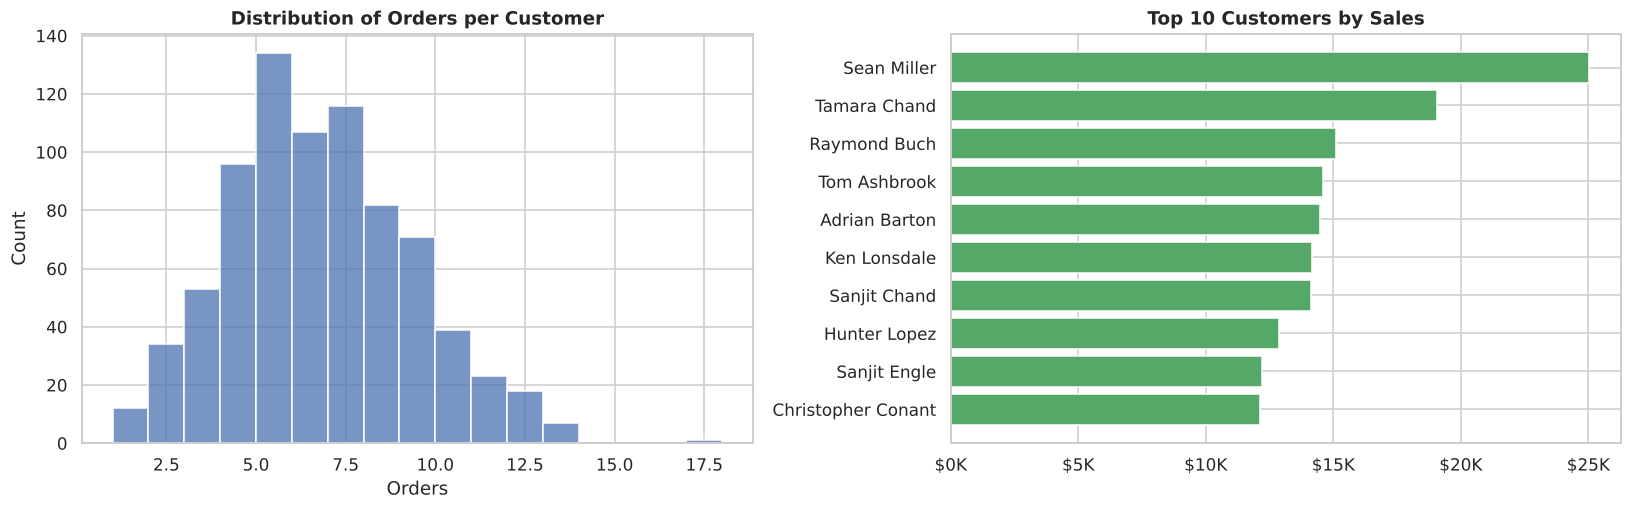

In [17]:
cust = df.groupby(["Customer ID", "Customer Name"]).agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique")
).reset_index().sort_values("Sales", ascending=False)

top20_share = cust.head(int(len(cust) * 0.2))["Sales"].sum() / cust["Sales"].sum()
print(f"Customers: {len(cust)} | Repeat customers (>1 order): {(cust['Orders'] > 1).mean():.1%}")
print(f"Median orders per customer: {cust['Orders'].median():.0f}")
print(f"Top 20% of customers generate {top20_share:.1%} of sales")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.histplot(cust["Orders"], bins=range(1, 19), ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of Orders per Customer")

top10 = cust.head(10).sort_values("Sales")
axes[1].barh(top10["Customer Name"], top10["Sales"], color="#55A868")
axes[1].xaxis.set_major_formatter(money)
axes[1].set_title("Top 10 Customers by Sales")
plt.tight_layout()
plt.show()

## 8. Executive Takeaways

> Figures below come from the outputs above (2015-2018 data; total sales **$2.30M**, total profit **$286K**, overall margin **12.5%**).

### 1. Business is growing, but 2016 stalled
Sales rose from **$484K (2015)** to **$733K (2018)**, about **+15% per year** compounded, and profit nearly doubled from $49.5K to $93.4K.
2016 was the exception, with sales down about 3% year over year before 2017 (+29%) and 2018 (+20%) rebounded.
**Action:** Understand what drove the 2016 dip and what drove the 2017-18 acceleration, then protect those drivers.

### 2. Strong, repeatable holiday seasonality
**November (1.84x), December (1.70x) and September (1.61x)** are the peak months; **February (0.31x) and January (0.50x)** are the weakest.
Q4 alone delivers about **38% of annual sales** versus **16% in Q1**, and Sep/Nov/Dec are the top-three months in every single year.
**Action:** Build inventory and staffing plans around the Sep-Dec window, and use Jan-Feb for clearance and B2B outreach rather than deep consumer discounts.

### 3. Discounts above 20% destroy profit
Margin is **29.5% with no discount**, **11.9% at 1-20%**, **-15.3% at 21-40%** and **-77.4% at 41-80%**.
Discount and profit are negatively correlated (**r = -0.22**), and lines discounted 30% or more lost **$135K**, close to the total $156K lost across all loss-making lines.
**Action:** Cap discounts at 20% unless approved, and require margin checks for any promotion above that.

### 4. Furniture sells like a leader but earns like a laggard
Furniture is the 2nd-largest category by sales (**$742K**) but earns only **$18K profit (2.5% margin)** versus **17%+ for Technology and Office Supplies**.
**Tables (-$17.7K)** and **Bookcases (-$3.5K)** lose money outright; Technology (**$145K profit**) and Office Supplies (**$122K**) generate about 94% of total profit.
**Action:** Reprice or renegotiate supplier cost for Tables and Bookcases, and shift marketing spend toward Technology (Copiers, Accessories, Phones) and Paper/Binders.

### 5. The Central region has a discounting problem, not a demand problem
Central posts **$501K sales but only a 7.9% margin**, versus **West at 14.9%** and East at 13.5%.
Central averages a **24% discount** (West: 11%), and **26% of Central sales carry discounts above 20%** versus just **2.4% in the West**. Furniture in Central is net loss-making (-$2.9K).
**Action:** Align Central discount authority with West practices; this is the single biggest region-level profit lever.

### 6. Customers are loyal and concentrated
**98% of the 793 customers are repeat buyers** (median 6 orders), and the **top 20% of customers generate about 48% of sales**.
By segment, Consumer is the largest (**$1.16M, 51% of sales**) but has the lowest margin (11.5%) versus Home Office (14.0%) and Corporate (13.0%).
**Action:** Launch a VIP/retention program for top accounts, and grow Corporate and Home Office where margins are healthier.

### Bonus: returns
About **5.9% of orders** appear in the Returns table; worth monitoring by category and region as a profit leak.

## 9. Assumptions & Limitations
- Profit margin = Profit / Sales at the order-line level; aggregate margins are computed as total profit / total sales (not an average of line margins).
- Returns are matched by Order ID and are *not* deducted from Sales/Profit; figures reflect gross sales.
- Discount bands are analytical groupings; the dataset has only 12 distinct discount values, so the band results are directional.
- Correlation (r = -0.22) does not prove causation: heavily discounted items may also be inherently low-margin products.
- The data covers a single retailer and four years; seasonality conclusions assume the pattern continues.